<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS06/datasetPBL/Praktikum1-ANNOY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install annoy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 3.6 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp313-cp313-linux_x86_64.whl size=520030 sha256=755644112b16153caee9f200fd49e8eea93057036da874553040eddbdc076017
  Stored in directory: /root/.cache/pip/wheels/fc/4e/87/f1f957e7382aa370452cff98276f51686924d5415e449800ed
Successfully built annoy


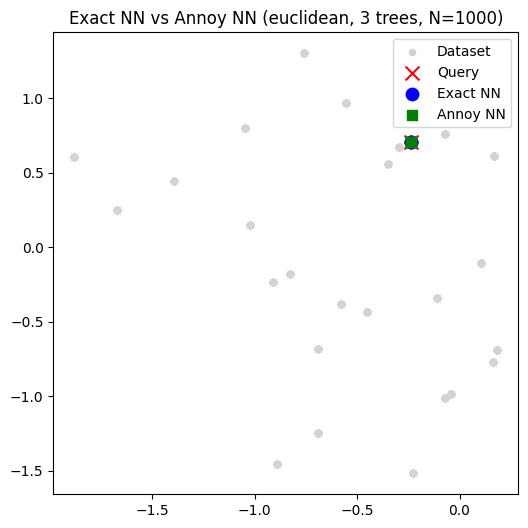

Distance Metrics  Tree  Jumlah data Hasil Index terdekat ENN vs ANN Waktu komputasi Vs (ms)
       Euclidean     3         1000       [92 91 85], [ 93  98 100]         5.3945 , 0.0288
       Euclidean     8         1000          [92 91 85], [83 87 88]         0.1736 , 0.0434
       Euclidean     3         2230    [853 854 855], [847 850 863]         0.2191 , 0.0317
         Angular     3         1000       [869 870 871], [86 91 97]         0.2518 , 0.0312
         Angular     8         1000       [869 870 871], [86 87 93]         0.2329 , 0.0403
         Angular     3         2230    [858 837 838], [838 847 850]         0.3412 , 0.0324


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.preprocessing import StandardScaler
from annoy import AnnoyIndex

# 1. Load dataset milikmu dan ambil fitur 2D (latitude, longitude)
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))

X_all = StandardScaler().fit_transform(df[['latitude', 'longitude']].values)

def jalankan_percobaan_2d(X_data, metric='euclidean', n_trees=3, plot_viz=False):
    np.random.seed(42)
    n_points = len(X_data)
    query = X_data[np.random.randint(0, n_points)]

    # 2. Exact NN (brute force)
    start = time.time()
    if metric == 'euclidean':
        distances = np.linalg.norm(X_data - query, axis=1)
    else:  # angular distance: sqrt(2 * (1 - cos_sim))
        X_norm = X_data / np.maximum(np.linalg.norm(X_data, axis=1, keepdims=True), 1e-12)
        q_norm = query / np.maximum(np.linalg.norm(query), 1e-12)
        distances = np.sqrt(np.maximum(0.0, 2.0 * (1.0 - X_norm @ q_norm)))
    idx_exact = np.argsort(distances)[:3]
    time_exact = (time.time() - start) * 1000  # ms

    # 3. Annoy NN
    f = 2
    t = AnnoyIndex(f, metric)
    for i, vec in enumerate(X_data):
        t.add_item(i, vec)
    t.build(n_trees)

    start = time.time()
    idx_ann = t.get_nns_by_vector(query, 3)
    time_ann = (time.time() - start) * 1000  # ms

    if plot_viz:
        plt.figure(figsize=(6, 6))
        plt.scatter(X_data[:, 0], X_data[:, 1], c="lightgray", s=20, label="Dataset")
        plt.scatter(query[0], query[1], c="red", marker="x", s=100, label="Query")
        plt.scatter(X_data[idx_exact, 0], X_data[idx_exact, 1], c="blue", s=80, label="Exact NN")
        plt.scatter(X_data[idx_ann, 0], X_data[idx_ann, 1], c="green", s=50, marker="s", label="Annoy NN")
        plt.legend()
        plt.title(f"Exact NN vs Annoy NN ({metric}, {n_trees} trees, N={n_points})")
        plt.show()

    return idx_exact, np.array(idx_ann), round(time_exact, 4), round(time_ann, 4)

# Jalankan seluruh variasi pada tabel pertama & tampilkan plot pada konfigurasi pertama
konfigurasi = [
    ('euclidean', 3, 1000, True),
    ('euclidean', 8, 1000, False),
    ('euclidean', 3, len(X_all), False),
    ('angular',   3, 1000, False),
    ('angular',   8, 1000, False),
    ('angular',   3, len(X_all), False),
]

hasil_tabel_1 = []
for metric, trees, n_data, viz in konfigurasi:
    idx_e, idx_a, t_e, t_a = jalankan_percobaan_2d(X_all[:n_data], metric=metric, n_trees=trees, plot_viz=viz)
    hasil_tabel_1.append({
        'Distance Metrics': metric.capitalize(),
        'Tree': trees,
        'Jumlah data': n_data,
        'Hasil Index terdekat ENN vs ANN': f"{idx_e}, {idx_a}",
        'Waktu komputasi Vs (ms)': f"{t_e} , {t_a}"
    })

print(pd.DataFrame(hasil_tabel_1).to_string(index=False))

In [4]:
import numpy as np
import pandas as pd
import time
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import euclidean_distances
from annoy import AnnoyIndex

# 1. Bentuk 20 fitur dari dataset kafe (5 fitur numerik + 15 fitur TF-IDF ulasan)
tfidf_15 = TfidfVectorizer(max_features=15, ngram_range=(1, 2))
X_txt15 = tfidf_15.fit_transform((df['name'] + " " + df['text'].astype(str))).toarray()
X_num5 = df[['rating_review', 'rating_cafe', 'review_count', 'latitude', 'longitude']].fillna(0).values

X_20 = StandardScaler().fit_transform(np.hstack([X_num5, X_txt15])).astype(np.float32)
n_items, n_features = X_20.shape  # (2230, 20)

np.random.seed(42)
query_idx = np.random.randint(0, n_items)
query = X_20[query_idx:query_idx + 1]

hasil_tabel_2 = []
for metric in ['euclidean', 'angular']:
    # Exact NN (brute force)
    start = time.time()
    if metric == 'euclidean':
        distances = euclidean_distances(query, X_20)[0]
    else:
        X_norm = X_20 / np.maximum(np.linalg.norm(X_20, axis=1, keepdims=True), 1e-12)
        q_norm = query / np.maximum(np.linalg.norm(query), 1e-12)
        distances = np.sqrt(np.maximum(0.0, 2.0 * (1.0 - (X_norm @ q_norm.T).ravel())))
    exact_idx = np.argsort(distances)[:5]
    exact_time = (time.time() - start) * 1000  # ms

    # Approx NN pakai Annoy (8 trees)
    annoy_index = AnnoyIndex(n_features, metric)
    for i in range(n_items):
        annoy_index.add_item(i, X_20[i])
    annoy_index.build(8)

    start = time.time()
    annoy_idx = np.array(annoy_index.get_nns_by_vector(query[0], 5))
    annoy_time = (time.time() - start) * 1000  # ms

    hasil_tabel_2.append({
        'Distance Metrics': metric.capitalize(),
        'Tree': 8,
        'Jumlah data': n_items,
        'Hasil Index terdekat ENN vs ANN': f"{exact_idx}, {annoy_idx}",
        'Waktu komputasi Vs (ms)': f"{round(exact_time, 4)} , {round(annoy_time, 4)}"
    })

print(pd.DataFrame(hasil_tabel_2).to_string(index=False))

Distance Metrics  Tree  Jumlah data                        Hasil Index terdekat ENN vs ANN Waktu komputasi Vs (ms)
       Euclidean     8         2230 [ 860 1855 1549 1125 1623], [ 860 1855 1549 1125  243]         1.5812 , 0.0749
         Angular     8         2230 [ 860 1855 1549 1125  243], [ 860 1855 1549 1125  243]         0.7324 , 0.0839
